# [기초-실습] 통계 101×데이터 분석: (4장) 추론통계~신뢰구간

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 표본조사 체험하기

**📘 문제**

- 온라인 쇼핑몰은 전체 고객 수가 너무 많아, 모든 고객을 조사하기 어렵습니다.

- 그래서 무작위로 고객 30명을 뽑아 평균 만족도를 계산하고 이를 전체 만족도의 추정값으로 사용하려 합니다.

- 이번 실습에서는 직접 표본을 뽑고, 표본 평균을 구해보며,
  **“표본마다 결과가 달라질 수 있다”**는 추론 통계의 핵심 개념을 체험해봅니다.

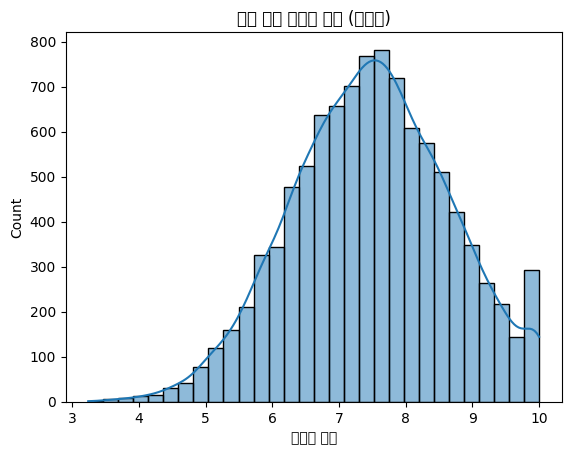

In [3]:
# 모집단 생성 (전체 고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({'score': population})

# 전체 모집단 시각화
sns.histplot(df_pop['score'], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 표본을 무작위로 여러 번 뽑아 보고, 표본 평균이 어떻게 변하는지 확인해봅시다.

- 히스토그램을 그리고, 표본 평균의 분포 형태를 관찰해봅시다.

In [4]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
# 여기에 코드를 작성해주세요.
# 모집단에서 무작위로 30명 추출 (비복원 추출)
sample = df_pop.sample(n=30, random_state=42)

# 표본 평균 계산
sample_mean = sample['score'].mean()
pop_mean = df_pop['score'].mean()

print(f"표본 평균: {sample_mean:.3f}")
print(f"모집단 평균: {pop_mean:.3f}")
print(f"차이: {sample_mean - pop_mean:.3f}")

표본 평균: 7.515
모집단 평균: 7.481
차이: 0.034


In [15]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
# 여기에 코드를 작성해주세요.
sample_means = []  # 표본 평균을 저장할 리스트

for i in range(500):
    sample = df_pop['score'].sample(n=30)  # 매번 다른 30명 추출
    sample_means.append(sample.mean())

print(f"저장된 표본 평균 개수: {len(sample_means)}")
print(f"표본 평균들의 평균: {np.mean(sample_means):.3f}")
print(f"모집단 평균: {df_pop['score'].mean():.3f}")


저장된 표본 평균 개수: 500
표본 평균들의 평균: 7.473
모집단 평균: 7.481


7.487513245537806


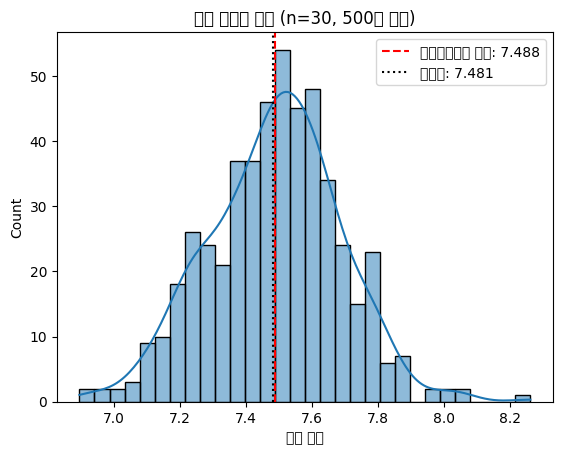

In [5]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
# 여기에 코드를 작성해주세요.
mean_of_means = np.mean(sample_means)
pop_mean = df_pop['score'].mean()

print(mean_of_means)

sns.histplot(sample_means, bins=30, kde=True)
plt.axvline(mean_of_means, color='red', linestyle='--',
            label=f'표본평균들의 평균: {mean_of_means:.3f}')
plt.axvline(pop_mean, color='black', linestyle=':',
            label=f'모평균: {pop_mean:.3f}')
plt.title("표본 평균의 분포 (n=30, 500회 반복)")
plt.xlabel("표본 평균")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 이 값은 전체 모집단 평균과 얼마나 비슷한가요?

- 표본을 1번 뽑았을 때와 500번을 반복해서 뽑았을 때, 표본 평균의 분포나 신뢰성에는 어떤 차이가 있나요

- 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 비슷한 결과가 나왔더라도 완전히 같지 않았다면, 그 이유는 무엇일까요?

- 표본 평균들의 분포는 어떤 모양인가요? 종 모양의 정규분포처럼 보이나요? 그렇다면 왜 그렇게 되는 걸까요?

In [ ]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1. 표본 평균은 모평균 값 주변에 많이 분포돼있다. 표본 평균의 평균값은 7.49 모평균은 7.48로 거의 똑같다

2. 표본을 1번만 뽑으면 평균값 하나만 얻게 되므로, 그 값이 모평균에 가까운지 먼지 알 수 없다. 이번에는 7.51로 모평균과 0.03 차이였지만 우연일 수 있다. 
    500번 반복하면 표본 평균이 어떤 범위에서 흔들리는지(분포)를 알 수 있다. 대부분은 모평균 근처에 있지만 가끔 멀리 떨어진 값도 나온다. 
    즉 반복을 통해 표본 평균 하나가 모평균에서 보통 얼마나 벗어나는지 파악할 수 있고, 이를 통해 표본 결과의 신뢰성을 판단할 수 있다.

3. 친구가 다른 표본을 뽑았다면 비슷한 값은 나오겠지만 정확히 같은 값이 나올 가능성은 매우 낮다. 
    무작위 추출에서는 매번 다른 사람들이 뽑히고, 모집단 안의 점수가 사람마다 다르기 때문에 표본 평균도 달라진다.

4. 표본 평균들의 분포는 모평균을 중심으로 좌우 대칭인 종 모양이다. 이는 중심극한정리 때문이다. 
    표본 크기가 충분히 크면 모집단 분포와 상관없이 표본 평균의 분포는 정규분포에 가까워진다. 
    한 표본 안에서 높은 점수와 낮은 점수가 서로 상쇄되기 때문에 평균이 극단적인 값이 되는 경우는 드물고 모평균 근처 값이 자주 나온다.

# 문제 2. 중심극한정리

**📘 문제**

- 현실에서는 모집단의 분포가 정규분포가 아닐 수도 있습니다.

- 예를 들어, 일부 고객은 매우 높은 점수를 주고, 대부분은 낮은 점수를 주는 만족도 분포가 있을 수 있죠. (예: 지수분포)

- 이처럼 원래 분포가 비정규분포여도,
  표본을 여러 번 뽑아 평균을 계산하면, 그 평균들의 분포는 정규분포에 가까워진다는 것을
  **중심극한정리(Central Limit Theorem)**라고 합니다.

- 이번 실습에서는 다양한 크기의 표본을 뽑아 평균을 계산하고,
  그 평균들의 분포가 어떻게 변하는지를 직접 실험해 봅니다.

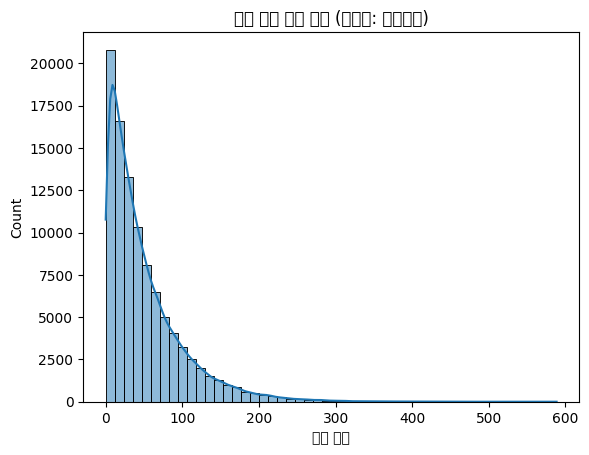

In [20]:
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

**📌 아래를 수행해 보세요:**

- 비대칭적인 모집단(지수분포)에서 무작위로 표본을 추출해 평균을 구해봅시다.

- 표본 크기를 바꿔가며, 표본 평균들의 분포가 어떻게 변화하는지 확인해봅시다.

- 히스토그램을 그리고, 분포의 모양을 관찰해봅시다.

- 표본 크기가 커질수록 표본 평균 분포의 모양과 **퍼진 정도(분산)**가 어떻게 변하는지 관찰해봅시다.

In [21]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다.
# 표본 크기 = 5일 때

# 여기에 코드를 작성해주세요.
sample_size = 5
sample_means_5 = []  # 표본 평균을 저장할 리스트

for i in range(1000):
    sample = np.random.choice(population, size=sample_size, replace=False)  # 5명 추출
    sample_means_5.append(sample.mean())

print(f"표본 평균 개수: {len(sample_means_5)}")
print(f"표본 평균들의 평균: {np.mean(sample_means_5):.3f}")
print(f"모평균: {population.mean():.3f}")

표본 평균 개수: 1000
표본 평균들의 평균: 49.410
모평균: 50.233


In [22]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
# sample_size = 30, 100

# 여기에 코드를 작성해주세요.
sample_size = 30
sample_means_30 = []

for i in range(1000):
    sample = np.random.choice(population, size=sample_size, replace=False)
    sample_means_30.append(sample.mean())

print(f"[n=30] 표본 평균들의 평균: {np.mean(sample_means_30):.3f}")
print(f"[n=30] 모평균: {population.mean():.3f}")


sample_size = 100
sample_means_100 = []

for i in range(1000):
    sample = np.random.choice(population, size=sample_size, replace=False)
    sample_means_100.append(sample.mean())

print(f"[n=100] 표본 평균들의 평균: {np.mean(sample_means_100):.3f}")
print(f"[n=100] 모평균: {population.mean():.3f}")

[n=30] 표본 평균들의 평균: 50.556
[n=30] 모평균: 50.233
[n=100] 표본 평균들의 평균: 50.212
[n=100] 모평균: 50.233


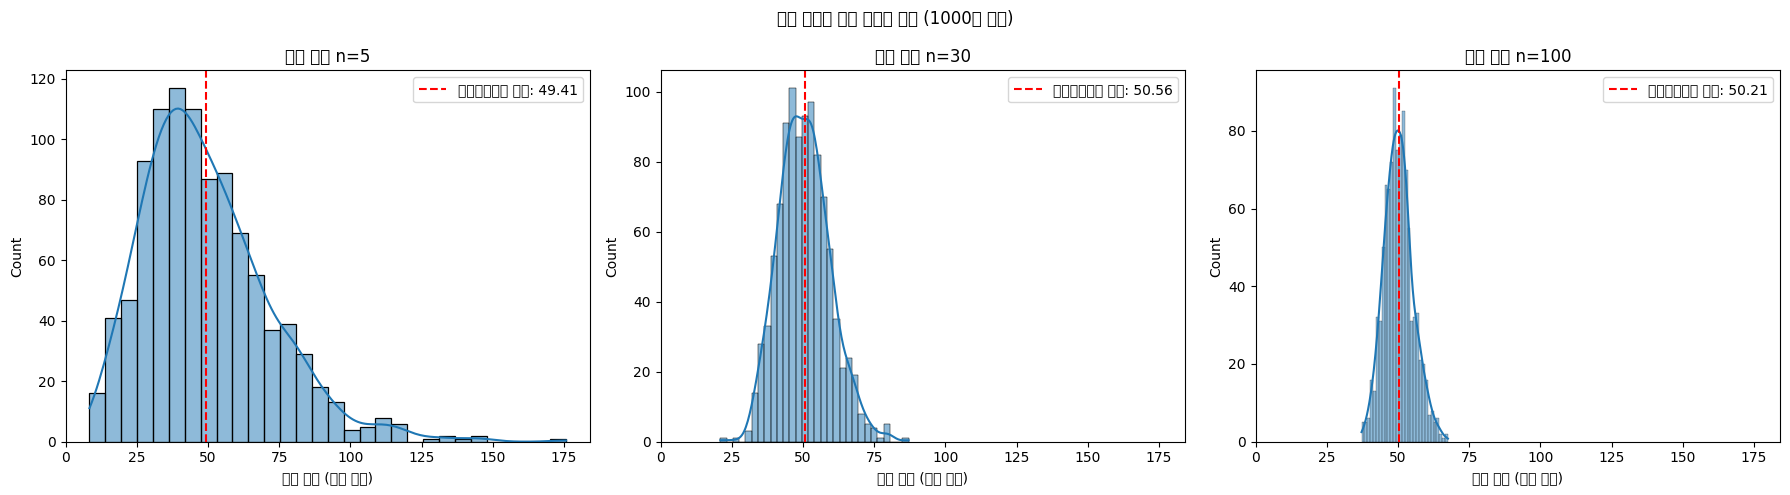

In [23]:
# [문제 2] Q3. 각 표본 크기별로 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 평균선을 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
results = {5: sample_means_5, 30: sample_means_30, 100: sample_means_100}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for ax, (n, means) in zip(axes, results.items()):
    mean_of_means = np.mean(means)

    sns.histplot(means, bins=30, kde=True, ax=ax)
    ax.axvline(mean_of_means, color='red', linestyle='--',
               label=f'표본평균들의 평균: {mean_of_means:.2f}')
    ax.set_title(f"표본 크기 n={n}")
    ax.set_xlabel("표본 평균 (구매 금액)")
    ax.legend()

plt.suptitle("표본 크기별 표본 평균의 분포 (1000회 반복)")
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을 때 (예: 5), 평균들의 분포는 어떤 모양인가요?

- 표본 크기가 커질수록 평균 분포의 모양은 어떤 변화를 보이나요?

- 원래 모집단은 비대칭이었는데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?

- 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?

- 표본 크기에 따라 **분포의 넓이(흩어짐)**는 어떻게 달라지나요?

In [ ]:
# [문제 2]데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1. 표본 크기가 5일 때 표본평균들의 분포는 모집단처럼 오른쪽으로 꼬리가 긴 비대칭 모양이다. 중심(표본평균들의 평균)은 모평균 50 근처에 있지만, 아직 종 모양은 아니다.

2. 표본 크기가 커질수록 오른쪽 꼬리가 줄어들면서 좌우대칭인 종 모양에 가까워지고, 분포의 폭이 좁아진다.

3. 표본평균은 여러 값을 섞은 결과이기 때문이다. n의 크기 즉 표본의 크기가 커질수록 극단적인 값들의 확률은 적어지고 큰값과 작은값은 상쇄가 된다.
    극단적인 평균이 나오려면 많은 값이 동시에 극단적이어야 해서 드물고, 모평균 근처 값은 흔해진다. 그래서 모집단이 비대칭이어도 표본평균의 분포는 종 모양인 정규분포에 가까워진다.
    
4. 중심극한정리는 모집단의 분포 모양과 상관없이, 표본 크기 n이 충분히 크면 표본평균의 분포가 모평균을 중심으로 한 정규분포에 가까워진다는 것이다. 
    이번 모집단은 오른쪽으로 치우친 지수분포였지만, n=30, 100으로 커지자 표본평균의 분포가 종 모양이 되는 것을 확인했다.

5. 표본 크기에 따라 상쇄되는 것이 많아지면서 분포의 넓이 즉 흩어짐이 줄어든다.

# 문제 3. 표준오차

**📘 문제**

- 앞선 실습에서 우리는 **표본 크기(n)가 커질수록 표본 평균들의 분포가 더 좁아진다**는 것을 확인했습니다.
- 이처럼 표본 평균들이 얼마나 흩어져 있는지(분포의 퍼진 정도)를 나타내는 값을 **표준오차(Standard Error, SE)**라고 부릅니다.
- 표준오차는 **표본 평균들의 표준편차**와 같은 의미이며, 이는 우리가 뽑은 표본 평균이 실제 모평균과 평균적으로 얼마나 떨어져 있을지를 나타내는 **'예상 오차의 크기'**입니다.

- 통계학적으로 이 표준오차는 **`SE = σ / √n`** (모집단 표준편차 / 표본 크기의 제곱근) 이라는 공식으로 계산할 수 있습니다.
- 이 공식은 **표본 크기(n)가 커질수록 표준오차(SE)가 작아진다**는 것을 명확히 보여줍니다.

- 이번 실습에서는 여러 크기의 표본을 뽑아, 시뮬레이션을 통해 얻은 **표본 평균들의 표준편차(실험값)**가 공식으로 계산한 **표준오차(이론값)**와 얼마나 일치하는지 직접 확인해봅니다.

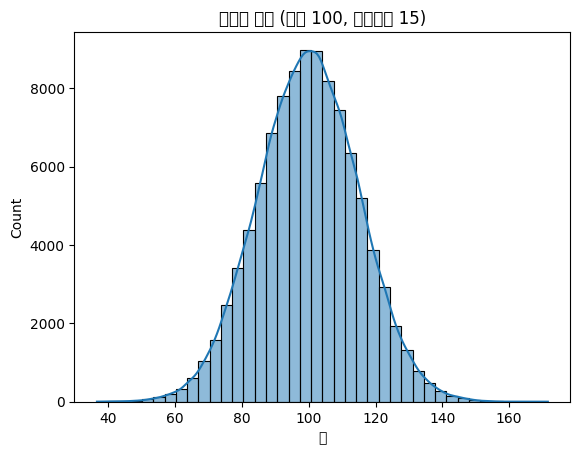

In [16]:
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 여러 크기의 표본(10, 30, 100, 500)을 각각 1000번 뽑고, 그 평균들을 구한 뒤, **표본 평균들의 표준편차(=실험적 표준오차)**를 계산해봅시다.

- 이 결과를 이론적인 표준오차 공식과 비교하는 표를 만들고, 시각화해봅시다.

   표본 크기(n)  표본평균 분포의 표준편차
0            10                     4.659
1            30                     2.786
2           100                     1.526
3           500                     0.663


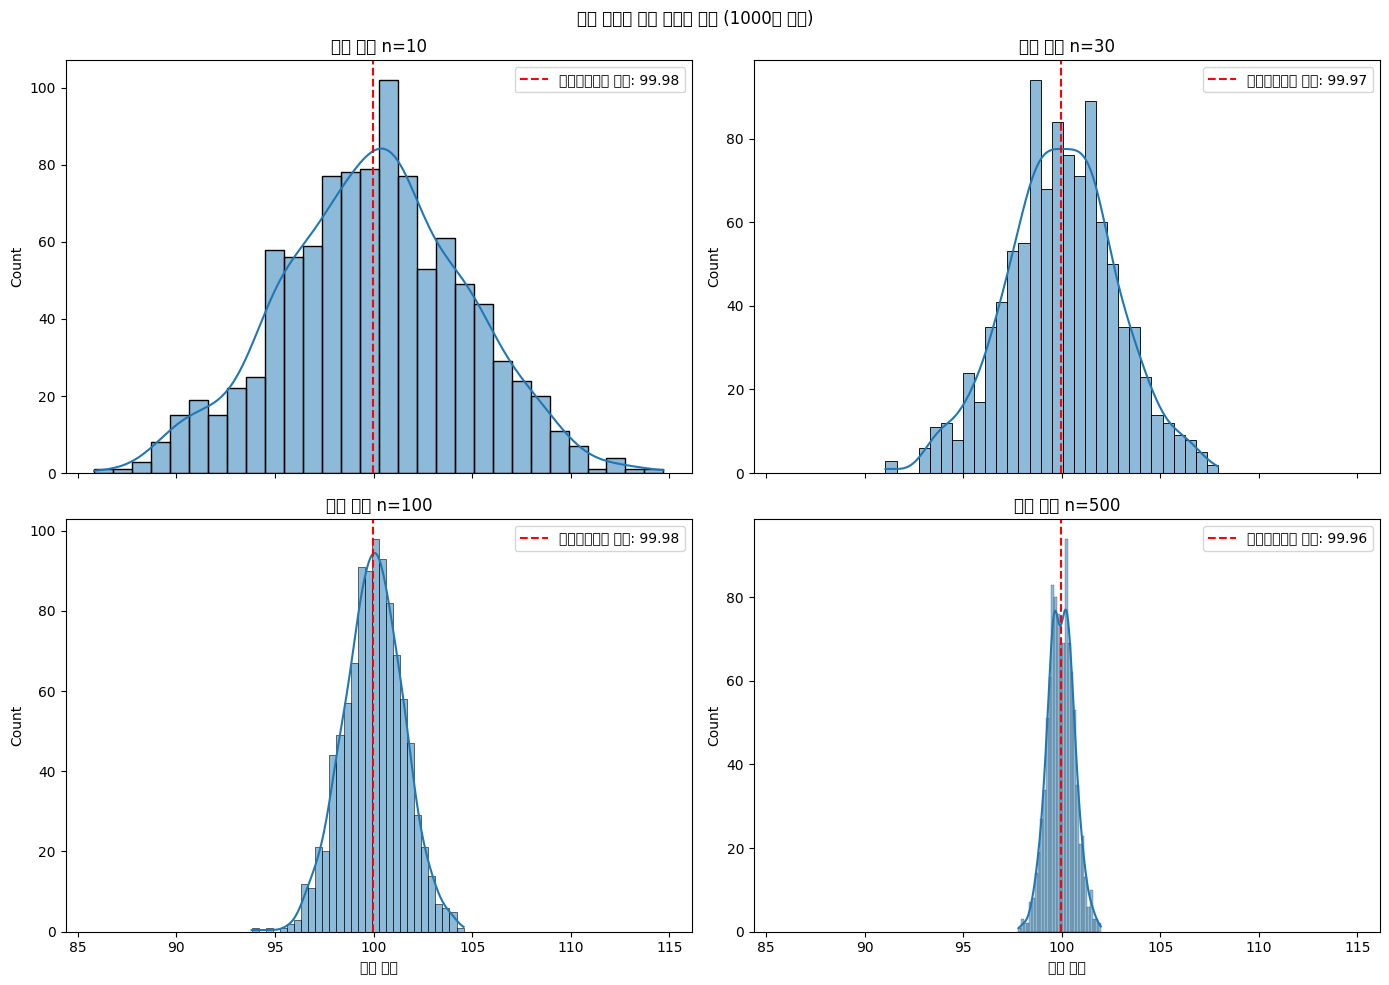

In [17]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.

# 여기에 코드를 작성해주세요.
sample_sizes = [10, 30, 100, 500]
n_repeat = 1000

sample_means_dict = {}   # 표본 크기별 표본평균 1000개 저장
std_list = []            # 표본 크기별 표본평균 분포의 표준편차 저장

for n in sample_sizes:
    means = []
    for i in range(n_repeat):
        sample = np.random.choice(population, size=n, replace=False)
        means.append(sample.mean())

    sample_means_dict[n] = means
    std_list.append(np.std(means, ddof=1))

# 표로 정리
result_df = pd.DataFrame({
    '표본 크기(n)': sample_sizes,
    '표본평균 분포의 표준편차': std_list
})

display(result_df.round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

for ax, n in zip(axes, sample_sizes):
    means = sample_means_dict[n]
    mean_of_means = np.mean(means)

    sns.histplot(means, bins=30, kde=True, ax=ax)
    ax.axvline(mean_of_means, color='red', linestyle='--',
               label=f'표본평균들의 평균: {mean_of_means:.2f}')
    ax.set_title(f"표본 크기 n={n}")
    ax.set_xlabel("표본 평균")
    ax.legend()

plt.suptitle("표본 크기별 표본 평균의 분포 (1000회 반복)")
plt.tight_layout()
plt.show()

In [18]:
# [문제 3] Q2. 이론적인 표준오차와 비교해봅시다.
# [공식] 표준오차(SE) = 모집단 표준편차 / √표본크기

# 여기에 코드를 작성해주세요.
pop_std = population.std()   # 모집단 표준편차

# 이론적 표준오차 = 모집단 표준편차 / √표본크기
theory_se_list = [pop_std / np.sqrt(n) for n in sample_sizes]

# 표에 추가해서 비교
result_df['이론적 표준오차'] = theory_se_list
result_df['차이(실험 - 이론)'] = result_df['표본평균 분포의 표준편차'] - result_df['이론적 표준오차']

print(f"모집단 표준편차: {pop_std:.3f}")
result_df.round(3)

모집단 표준편차: 15.033
   표본 크기(n)  표본평균 분포의 표준편차  이론적 표준오차  차이(실험 - 이론)
0            10                     4.659            4.754             -0.095
1            30                     2.786            2.745              0.041
2           100                     1.526            1.503              0.023
3           500                     0.663            0.672             -0.009


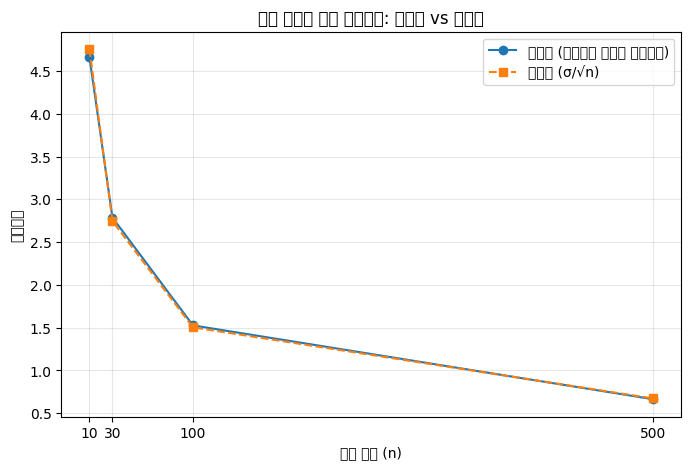

In [19]:
# [문제 3] Q3. 실험값과 이론값을 시각화해봅시다.
# 표본 크기를 x축, 표준오차를 y축으로 한 꺾은선 그래프를 그려봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(8, 5))

plt.plot(sample_sizes, std_list, marker='o', label='실험값 (표본평균 분포의 표준편차)')
plt.plot(sample_sizes, theory_se_list, marker='s', linestyle='--', label='이론값 (σ/√n)')

plt.title("표본 크기에 따른 표준오차: 실험값 vs 이론값")
plt.xlabel("표본 크기 (n)")
plt.ylabel("표준오차")
plt.xticks(sample_sizes)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

- 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?

- 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?

- 왜 표본 크기가 커질수록 표준오차는 작아질까요?

In [ ]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.
1. 표본 크기가 작을수록(n=10) 표본평균의 분포는 종 모양이지만 다른 표본 크기보다 넓게 퍼져 있다. 다만 평균을 낸 값이기 때문에 모집단보다는 좁다.

2. 표본 크기가 커질수록 평균 분포는 분포의 넓이가 줄어들면서 모평균 중심으로 근처의 값들이 더 많아졌다.

3. 실험값과 이론값은 거의 같다. 예를 들어 n=10일 때 실험값은 4.659 , 이론값은 약 4.754로 차이가 -0.095정도였고, 꺾은선 그래프에서도 두 선이 거의 겹쳤다. 
    약간의 차이는 무한히가 아니라 1000번만 반복했기 때문에 생긴 우연한 오차이다.

4. 표본 크기가 커질수록 큰 값과 작은 값이 더 많이 상쇄되고, 한 사람의 값이 평균에 주는 영향도 작아진다. 그래서 극단적인 평균이 잘 나오지 않고 모평균에 가까운 값이 나올 가능성이 높아진다. 
    표준오차 식에서도 이를 확인할 수 있다. 표준오차 = σ/√n이며, 표준오차는 n이 커질수록 √n에 반비례해서 작아진다.

# 문제 4. 신뢰구간 계산과 해석

**📘 문제**

- 표본 평균은 모집단 평균을 추정하는 좋은 점 추정(Point Estimation) 값이지만, 표본오차 때문에 정확히 일치하지는 않습니다.

- 그래서 우리는 "모집단 평균이 아마 이 범위 안에 있을 것이다"라고 **구간으로 추정(Interval Estimation)**하는 것이 더 합리적입니다. 이때 사용하는 개념이 바로 **신뢰구간(Confidence Interval)**입니다.

- 신뢰구간은 표본평균 ± 오차범위 형태로 계산되며, 이 오차범위는 신뢰수준(예: 95%, 99%)과 표본오차에 의해 결정됩니다.

- 이번 실습에서는 **모집단 표준편차(σ)를 알 때(z-분포)**와 **모를 때(t-분포)**의 신뢰구간을 각각 계산해보고, 신뢰수준에 따라 구간의 폭이 어떻게 변하는지 확인해봅니다.

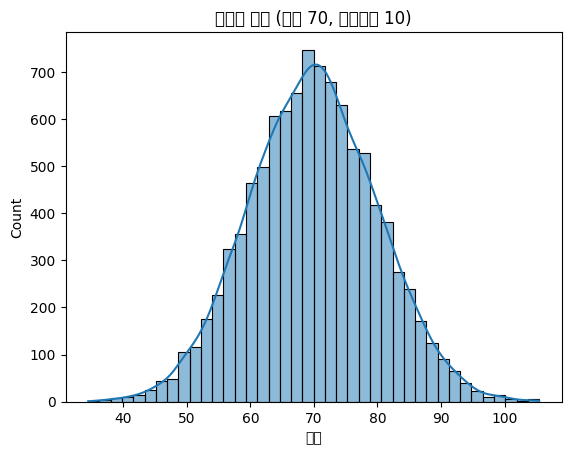

In [6]:
# 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 30명을 무작위로 뽑아 평균, 표준편차, 표준오차를 계산해보세요.

- 95% 신뢰구간을 z-분포와 t-분포를 각각 사용해서 계산해보세요.

- 신뢰수준을 바꿨을 때(90%, 99%) 신뢰구간이 어떻게 변하는지 확인해보세요.

In [7]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.

# 여기에 코드를 작성해주세요.
n = 30

# 표본 30명 무작위 추출
sample = np.random.choice(population, size=n, replace=False)

# 표본 평균, 표본 표준편차, 표준오차
sample_mean = sample.mean()
sample_std = sample.std(ddof=1)        # 표본 표준편차
se = sample_std / np.sqrt(n)           # 표준오차 = 표본 표준편차 / √n

print(f"표본 평균: {sample_mean:.3f}")
print(f"표본 표준편차: {sample_std:.3f}")
print(f"표준오차: {se:.3f}")

표본 평균: 67.604
표본 표준편차: 11.078
표준오차: 2.023


In [8]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.
from scipy import stats

sigma = population.std()                 # 모집단 표준편차 (알고 있다고 가정)
se_z = sigma / np.sqrt(n)                # 표준오차 = 모집단 표준편차 / √n

z = stats.norm.ppf(0.975)                # 95% 신뢰수준의 z값 (약 1.96)

lower = sample_mean - z * se_z
upper = sample_mean + z * se_z

print(f"모집단 표준편차: {sigma:.3f}")
print(f"표준오차: {se_z:.3f}")
print(f"z값: {z:.3f}")
print(f"95% 신뢰구간: ({lower:.3f}, {upper:.3f})")

모집단 표준편차: 10.005
표준오차: 1.827
z값: 1.960
95% 신뢰구간: (64.024, 71.184)


In [9]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.
df = n - 1                                   # 자유도
t = stats.t.ppf(0.975, df)                   # 95% 신뢰수준의 t값

lower_t = sample_mean - t * se               # se = 표본 표준편차 / √n (Q1에서 계산)
upper_t = sample_mean + t * se

print(f"자유도: {df}")
print(f"표준오차: {se:.3f}")
print(f"t값: {t:.3f}")
print(f"95% 신뢰구간: ({lower_t:.3f}, {upper_t:.3f})")

자유도: 29
표준오차: 2.023
t값: 2.045
95% 신뢰구간: (63.467, 71.740)


In [10]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.

# 여기에 코드를 작성해주세요.
conf_levels = [0.90, 0.95, 0.99]
ci_results = []

for conf in conf_levels:
    t_val = stats.t.ppf(1 - (1 - conf) / 2, df)   # 90% → 0.95, 95% → 0.975, 99% → 0.995
    lower = sample_mean - t_val * se
    upper = sample_mean + t_val * se
    ci_results.append([f"{int(conf*100)}%", t_val, lower, upper, upper - lower])

ci_df = pd.DataFrame(ci_results, columns=['신뢰수준', 't값', '하한', '상한', '구간 폭'])
display(ci_df.round(3))


#z
ci_results_z = []

for conf in conf_levels:
    z_val = stats.norm.ppf(1 - (1 - conf) / 2)    # 90% → 0.95, 95% → 0.975, 99% → 0.995
    lower = sample_mean - z_val * se_z
    upper = sample_mean + z_val * se_z
    ci_results_z.append([f"{int(conf*100)}%", z_val, lower, upper, upper - lower])

ci_df_z = pd.DataFrame(ci_results_z, columns=['신뢰수준', 'z값', '하한', '상한', '구간 폭'])
display(ci_df_z.round(3))

  신뢰수준    t값    하한    상한  구간 폭
0      90%  1.699  64.167  71.040    6.873
1      95%  2.045  63.467  71.740    8.273
2      99%  2.756  62.029  73.179   11.150
  신뢰수준    z값    하한    상한  구간 폭
0      90%  1.645  64.599  70.608    6.009
1      95%  1.960  64.024  71.184    7.160
2      99%  2.576  62.899  72.309    9.410


**🧠 데이터를 어떻게 읽을까요?**

- z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?

- 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?

- 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?

- 이 데이터가 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?

In [ ]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.
1. z분포의 구간은 (64.024, 71.184)로 폭이 약 7.16, t분포의 구간은 (63.467, 71.740)로 폭이 약 8.27로 z분포의 구간폭이 더 좁다
    t분포는 모집단 표준편차를 모르는 불확실성을 반영해서 t값(2.045)이 z값(1.96)보다 크기 때문이다.

2. 신뢰수준이 높아질수록 신뢰구간의 폭은 넓어진다. 신뢰수준은 표본을 뽑아 구간을 만드는 일을 100번 반복했을 때 모평균을 포함하는 구간의 비율이다(95%면 약 95번). 
    더 높은 비율로 모평균을 포함하려면 구간을 더 넓게 잡아야 하므로, 신뢰수준이 높을수록 곱하는 임계값이 커지고(90%: 1.645, 95%: 1.96, 99%: 2.576) 구간이 넓어진다.

3. 신뢰구간이 넓다는 것은 좋기만 하거나 나쁘기만 한 것이 아니다. 넓은 구간은 모평균을 포함할 가능성이 높아 신뢰도는 높지만, 범위가 넓어 모평균이 정확히 얼마인지 추정하기는 어렵다(정밀도가 낮다). 
    따라서 신뢰도와 정밀도 사이에서 균형이 필요하다. 하지만 신뢰수준을 유지하면서 구간을 좁히려면 표본 크기를 늘리는 것이 좋다.

4. 신뢰구간을 활용하면 고객 만족도를 하나의 값이 아니라 범위로 판단할 수 있다. 예를 들어 목표 만족도가 75점이라면 95% 신뢰구간의 상한(71.7점)도 목표보다 낮으므로 만족도 개선 전략이 필요하다고 판단할 수 있다.
    아니면 마케팅 활동 전후의 신뢰구간을 비교해 겹치지 않으면 캠페인 효과가 있다고 볼 수 있다.

# 문제 5. 미니 프로젝트 - 고객 만족도 신뢰구간 추정

**📘 문제**

- 전체 고객 10,000명을 대상으로 만족도 조사를 하는 것은 시간과 비용이 많이 듭니다.
- 그래서 우리는 무작위로 일부 고객만 조사하여, 전체 고객의 평균 만족도를 추정하려 합니다.

- 이 프로젝트에서는 실제와 같은 상황을 가정하여, 표본을 뽑고 신뢰구간을 계산한 뒤, 이 결과를 바탕으로 마케팅 전략에 어떻게 활용할 수 있을지까지 생각해보는 실습을 진행합니다.

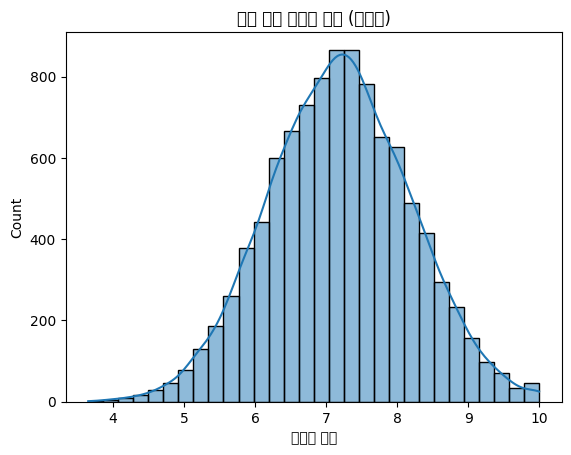

In [11]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단을 생성하고, 거기서 표본을 40명 뽑아 평균을 계산해봅시다.

- 표본 평균과 표준편차를 바탕으로 95% 신뢰구간을 계산해봅시다.

- 히스토그램을 그리고 신뢰구간을 시각화해봅시다.

- 이 결과를 어떻게 해석하고, 마케팅 전략에 활용할 수 있을지 생각해봅시다.

In [12]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 여기에 코드를 작성해주세요. 
n = 40

sample = np.random.choice(population, size=n, replace=False)

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)     # 표본 표준편차

print(f"표본 평균: {sample_mean:.3f}")
print(f"표본 표준편차: {sample_std:.3f}")

표본 평균: 7.134
표본 표준편차: 1.029


In [13]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
# 여기에 코드를 작성해주세요.
from scipy import stats

se = sample_std / np.sqrt(n)            # 표준오차 = 표본 표준편차 / √n
df = n - 1                              # 자유도
t_val = stats.t.ppf(0.975, df)          # 95% 신뢰수준의 t값

lower = sample_mean - t_val * se
upper = sample_mean + t_val * se

print(f"표준오차: {se:.3f}")
print(f"자유도: {df}, t값: {t_val:.3f}")
print(f"95% 신뢰구간: ({lower:.3f}, {upper:.3f})")

표준오차: 0.163
자유도: 39, t값: 2.023
95% 신뢰구간: (6.805, 7.463)


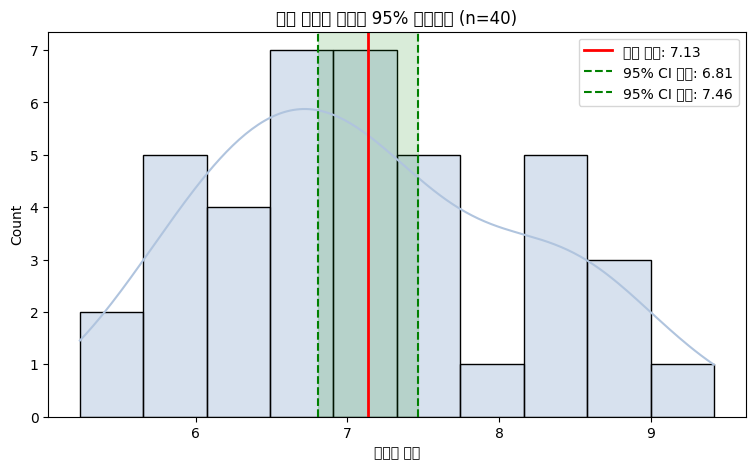

In [14]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
#  여기에 코드를 작성해주세요.
plt.figure(figsize=(9, 5))

sns.histplot(sample, bins=10, kde=True, color='lightsteelblue')

plt.axvline(sample_mean, color='red', linestyle='-', linewidth=2,
            label=f'표본 평균: {sample_mean:.2f}')
plt.axvline(lower, color='green', linestyle='--',
            label=f'95% CI 하한: {lower:.2f}')
plt.axvline(upper, color='green', linestyle='--',
            label=f'95% CI 상한: {upper:.2f}')
plt.axvspan(lower, upper, color='green', alpha=0.15)   # 신뢰구간 영역 색칠

plt.title("표본 데이터 분포와 95% 신뢰구간 (n=40)")
plt.xlabel("만족도 점수")
plt.legend()
plt.show()

In [ ]:
# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까요?
# 여기에 의견을 작성해주세요.

표본 40명으로 95% 신뢰구간을 구했을 때 전체 고객 만족도 평균은 6.8점에서 7.46점 사이에 있을 것으로 추정된다. 
    만약 목표 점수가 7.5점이라면 신뢰구간의 상한인 7.46점도 목표보다 낮기 때문에 지금 만족도는 목표에 못 미친다고 볼 수 있다.
    그래서 만족도를 올리기 위한 전략이 필요하다.

하지만 상한과 목표의 차이가 0.04점밖에 안 되기 때문에 서비스 전체를 바꾸기보다는 만족도가 낮은 고객들을 중심으로 개선하는 게 더 효과적일 것 같다.
    먼저 만족도가 낮은 고객에게 왜 불만족했는지 조사하여 원인에 따라 쿠폰이나 혜택 등을 통해 개선할 수 있다
    개선 활동을 한 뒤에 다시 표본을 뽑아서 신뢰구간을 구해 본다. 새로 구한 신뢰구간의 하한이 7.5점보다 높으면 목표를 달성했다고 판단할 수 있다. 

**🧠 데이터를 어떻게 읽을까요?**

- 신뢰구간은 몇 점에서 몇 점 사이인가요?

- 이 구간은 전체 모집단 평균을 포함하고 있나요?

- 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있을까요?

- 만약 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?

In [ ]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.
1. 신뢰구간은 6.805점과 7.463사이이다

2. 모평균을 계산해 보니 약 7.2점(직접 출력한 값)이었고, 신뢰구간 6.805~7.463점 안에 들어가므로 이 구간은 모평균을 포함하고 있다.

3. 고객 만족도가 충분히 높은지는 목표 점수에 따라 다르다. 목표 점수가 6.5점처럼 신뢰구간의 하한(6.805점)보다 낮으면 충분히 높다고 할 수 있다. 
    목표 점수가 7.0점처럼 신뢰구간 안에 있으면 실제 평균이 목표보다 높을 수도 낮을 수도 있어서 판단하기 어렵다. 목표 점수가 7.5점처럼 신뢰구간의 상한(7.463점)보다 높으면 만족도가 목표보다 낮다고 볼 수 있다.

4. 신뢰구간이 너무 넓게 나왔다는 것은 그만큼 불확실성이 크다는 것이다. 그 이유는 표본의 크기가 작거나 표본 값의 변동이 크다는 것으로 표본의 크기를 올림으로써 개선할 수 있다.